# Clifford/T circuit experiments

Build the circuits explicitly, try Pauli checks, then compare fidelity, retained shots and cost. These are reproducible reconstructions, not a claim that this file predates the game. This notebook revision is AI-assisted.

Run `python scripts/execute_track_notebook.py` in the environment installed from `notebooks/requirements.txt`. Every displayed result is computed during execution. The saved study JSON is checked at the end; it supplies no circuits or scores.

1. [Circuits](#circuits)
2. [Coherent checks](#checks)
3. [Paulice insertion and post-selection](#paulice)
4. [Observable study](#observable)
5. [Comparison and reproduction](#comparison)

In [1]:
from pathlib import Path
import sys, os, time, json, warnings
from importlib.metadata import version
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"backend").exists())
sys.path.insert(0, str(ROOT))
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"
START = time.perf_counter()
SEED, SHOTS = 2026, 1024
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Pauli
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel as AerNoiseModel, depolarizing_error
from qiskit_paulice import add_pauli_checks
from qiskit_paulice.noise_models import NoiseModel as PauliceNoiseModel
from backend.quantum_core.paulice import optimize_clifford
from backend.research import expectation, run_research
from backend.models import ResearchRequest
from scripts.run_track_experiments import score, z_shell, resources
from scripts.level_design_analysis import table, draw, panels, figure, assert_same_circuit

<a id="circuits"></a>
## Build a matched circuit family

Three data qubits, one or three backbone repetitions, and four fixed doping slots. Replacing an identity by T keeps the number of serialized instructions fixed. A uniform depolarizing channel of strength 0.01 follows every instruction on every live wire, including helper/check gates. This is synthetic noise; no device calibration or hardware run is claimed.

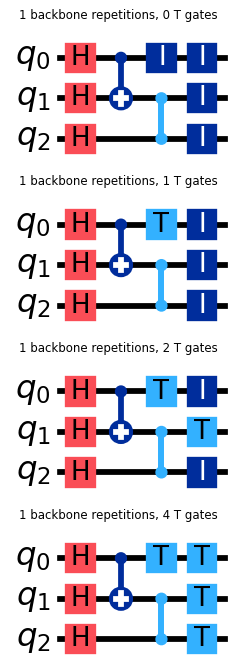

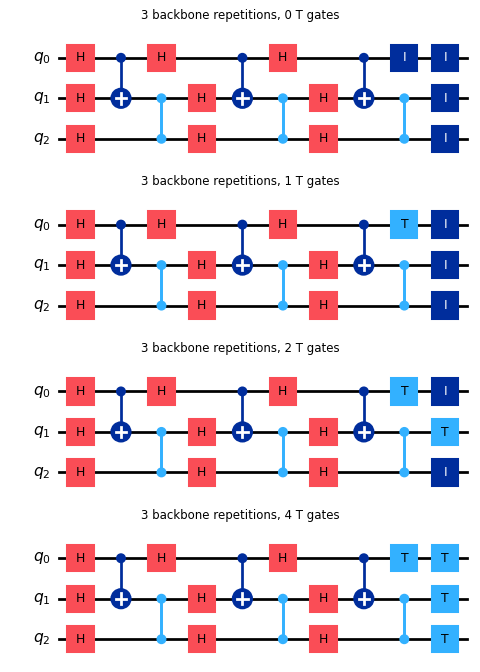

In [2]:
def design(repetitions, t_count):
    qc = QuantumCircuit(3)
    for _ in range(repetitions):
        qc.h(0)
        qc.h(1)
        qc.cx(0, 1)
        qc.h(2)
        qc.cz(1, 2)
    for slot in range(4):
        if slot < t_count:
            qc.t(slot % 3)
        else:
            qc.id(slot % 3)
    return qc

circuits = {(repetitions, t):design(repetitions, t)
            for repetitions in (1, 3) for t in (0, 1, 2, 4)}
for repetitions in (1, 3):
    panels([(f"{repetitions} backbone repetitions, {t} T gates", circuits[repetitions,t])
            for t in (0, 1, 2, 4)])

<a id="checks"></a>
## Try all seven nonidentity Z/I openings

The shared constructor propagates each Pauli through the explicitly built circuit, inserts the signed inverse closing check, and rejects non-Pauli intermediate crossings. Exact Aer density matrices give F_ps and S_keep. No game shot budget is assigned to this matched study, so Trusted Fidelity is N/A. The unbudgeted comparison uses correct-shot yield, F_ps × S_keep.

repetitions,tCount,opening,valid
1,0,IIZ,True
1,0,IZI,True
1,0,IZZ,True
1,0,ZII,True
1,0,ZIZ,True
1,0,ZZI,True
1,0,ZZZ,True
1,1,IIZ,False
1,1,IZI,True
1,1,IZZ,False


repetitions,tCount,dataQubits,payloadDepth,method,uncheckedFidelity,fidelity,retention,score,correct_shot_yield,minimumKept,trusted_fidelity,addedAncillas,addedTwoQubit,addedDepth,engine,targets
1,0,3,4,unchecked,0.854089,0.854089,1,0.854089,0.854089,—,—,0,0,0,none,[]
1,0,3,4,custom-Z-search,0.854089,0.853098,0.834486,0.711898,0.711898,—,—,1,4,6,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.838895,0.86985,0.729713,0.729713,—,—,1,3,5,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.837674,0.87736,0.734942,0.734942,—,—,1,3,5,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.83858,0.86985,0.729439,0.729439,—,—,1,3,4,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.859783,0.811763,0.69794,0.69794,—,—,1,5,6,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.846952,0.844725,0.715441,0.715441,—,—,1,4,5,custom full-span Z/I search,—
1,0,3,4,custom-Z-search,0.854089,0.85647,0.799478,0.684729,0.684729,—,—,1,6,7,custom full-span Z/I search,—
1,1,3,4,unchecked,0.854089,0.854089,1,0.854089,0.854089,—,—,0,0,0,none,[]
1,1,3,4,custom-Z-search,0.854089,0.838895,0.86985,0.729713,0.729713,—,—,1,3,5,custom full-span Z/I search,—


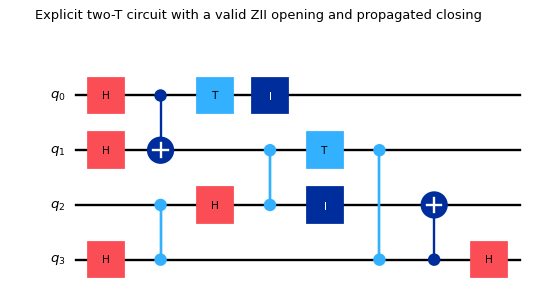

Non-Pauli intermediate transport rejected before scoring; valid shells have no noiseless false syndrome.


In [3]:
from itertools import product
rows, admissibility = [], []
for (repetitions, t_count), base in circuits.items():
    baseline = score(base, base)
    variants = [("unchecked", base, dict(engine="none", targets=[]))]
    for letters in product("IZ", repeat=3):
        label = "".join(letters)
        if label == "III":
            continue
        checked = z_shell(base, label)
        admissibility.append(dict(repetitions=repetitions, tCount=t_count,
                                  opening=label, valid=checked is not None))
        if checked is not None:
            variants.append(("custom-Z-search", checked,
                dict(engine="custom full-span Z/I search", opening=label)))
    for method, circuit, metadata in variants:
        ideal = score(circuit, base, noisy=False)
        assert abs(ideal["fidelity"]-1) < 1e-8 and abs(ideal["retention"]-1) < 1e-8
        metrics = score(circuit, base)
        rows.append(dict(repetitions=repetitions, tCount=t_count, dataQubits=3,
            payloadDepth=base.depth(), method=method, uncheckedFidelity=baseline["fidelity"],
            **metrics, minimumKept=None, trusted_fidelity=None,
            **resources(circuit, base), **metadata))
table(admissibility)
table(rows)
chosen = z_shell(circuits[1,2], "ZII")
assert chosen is not None
draw(chosen, "Explicit two-T circuit with a valid ZII opening and propagated closing")
assert z_shell(circuits[1,4], "IZZ") is None
print("Non-Pauli intermediate transport rejected before scoring; valid shells have no noiseless false syndrome.")

<a id="paulice"></a>
## Paulice: insert, inspect, execute, filter

This separate Clifford experiment calls `add_pauli_checks` directly. Measurements are required; transpilation preserves the payload and converts it into the add-on's supported basis. Compare target orders and helper budgets, keep every insertion stage, and inspect support and native gamma. Paulice's own synthetic `NoiseModel` estimates costs; it does not execute the circuit. Aer performs execution below. Neither gamma nor this parity-observable estimate is the game score.

order,stage,checks,nativeGamma,metric,targetQubits,support,addedAncillas,addedTwoQubit,addedDepth
[0],0,0,1.04088,gamma,[],[],0,0,-1
[1],0,0,1.04088,gamma,[],[],0,0,-1
[1],1,1,1.02707,gamma,[1],"[[0, 3]]",1,2,4
"[0, 1]",0,0,1.04088,gamma,[],[],0,0,-1
"[0, 1]",1,1,1.02707,gamma,[1],"[[0, 3]]",1,2,4
"[1, 0]",0,0,1.04088,gamma,[],[],0,0,-1
"[1, 0]",1,1,1.02707,gamma,[1],"[[0, 3]]",1,2,4


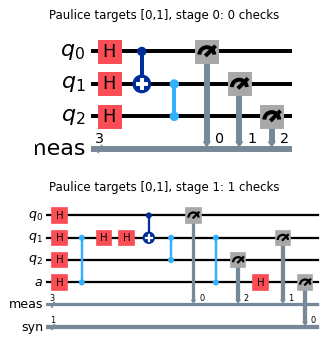

The game's shared Clifford adapter agrees with the direct add-on call.


In [4]:
base = circuits[1,0].copy()
base.data = [g for g in base.data if g.operation.name != "id"]
measured = base.copy()
measured.measure_all()
native_input = transpile(measured, basis_gates=["h","s","sdg","x","z","cx","cz"],
                         optimization_level=0, seed_transpiler=SEED)
native_noise = PauliceNoiseModel(gate_noise=.01, readout_noise=0)
paths = {}
native_rows = []
for targets in ([0], [1], [0,1], [1,0]):
    path = add_pauli_checks(native_input, targets, native_noise,
                           cost="gamma", method="windowed", seed=SEED,
                           check_qreg_name="a", check_creg_name="syn")
    paths[tuple(targets)] = path
    for stage, candidate in enumerate(path):
        assert candidate.circuit.num_qubits-base.num_qubits <= len(targets)
        native_rows.append(dict(order=targets, stage=stage, checks=len(candidate.check_qubits),
            nativeGamma=float(candidate.cost), metric=candidate.cost_metric,
            targetQubits=list(candidate.target_qubits), support=[list(s) for s in candidate.check_support],
            **resources(candidate.circuit, measured)))
table(native_rows)
panels([(f"Paulice targets [0,1], stage {i}: {len(c.check_qubits)} checks", c.circuit)
        for i,c in enumerate(paths[0,1])])
adapter = optimize_clifford(measured, [0,1], ancilla_limit=2, seed=SEED)
assert abs(float(adapter.cost)-float(paths[0,1][-1].cost)) < 1e-12
print("The game's shared Clifford adapter agrees with the direct add-on call.")

In [5]:
# Match a simple gate-local Aer model to the disclosed native noise rate.
aer_noise = AerNoiseModel()
aer_noise.add_all_qubit_quantum_error(depolarizing_error(.01,1), ["h","s","sdg","x","z"])
aer_noise.add_all_qubit_quantum_error(depolarizing_error(.01,2), ["cx","cz"])
simulator = AerSimulator(noise_model=aer_noise, max_parallel_threads=1)
observable = Pauli("ZZZ")
observed = []
for stage, candidate in enumerate(paths[0,1]):
    executable = transpile(candidate.circuit, basis_gates=["h","s","sdg","x","z","cx","cz"],
                           optimization_level=0, seed_transpiler=SEED)
    counts = simulator.run(executable, shots=SHOTS, seed_simulator=SEED).result().get_counts()
    raw, _ = expectation(counts, executable, observable)
    selected, kept = expectation(counts, executable, observable, candidate.get_postselection_method())
    observed.append(dict(stage=stage, shots=SHOTS, kept=kept, discarded=SHOTS-kept,
                         retainedFraction=kept/SHOTS, rawZZZ=raw, postselectedZZZ=selected))
table(observed)
print("Ideal ZZZ expectation:", float(Statevector.from_instruction(base).expectation_value(observable).real))
print("Filtering uses CheckedCircuit.get_postselection_method(), not an assumed ancilla-bit convention.")
print("ZZZ alone is an observable estimate, not full-state fidelity.")

stage,shots,kept,discarded,retainedFraction,rawZZZ,postselectedZZZ
0,1024,1024,0,1,-0.0136719,-0.0136719
1,1024,979,45,0.956055,0,-0.00715015


Ideal ZZZ expectation: 0.0
Filtering uses CheckedCircuit.get_postselection_method(), not an assumed ancilla-bit convention.
ZZZ alone is an observable estimate, not full-state fidelity.


<a id="observable"></a>
## Full stabilizer-observable benchmark

The existing research function repeats a separate Clifford benchmark and estimates the projector from all seven nonidentity stabilizers. It calls the same Paulice adapter separately for each measurement setting, applies the add-on's post-selection filter, and reports shots/resources. Its gate-local/readout noise differs from the uniform all-wire coherent study above; the two estimators are not merged. The explicit backbone below is checked against that API's benchmark before it runs.

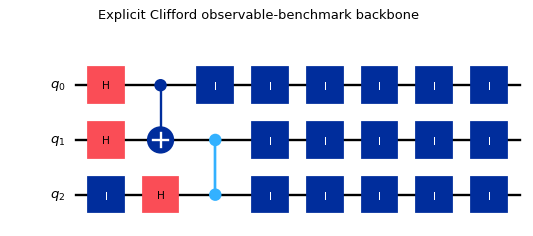

repetitions,targets,F_estimate,S_keep,checks,settings,totalShots,keptShots,addedTwoQubit,addedDepth
1,[0],0.924072,1,0,7,7168,7168,0,0
1,[1],0.943386,0.941546,1,7,7168,6749,3,10
1,"[0, 1]",0.943386,0.941546,1,7,7168,6749,3,10
1,"[1, 0]",0.943386,0.941546,1,7,7168,6749,3,10
3,[0],0.937029,0.922294,1,7,7168,6611,3,7
3,[1],0.95006,0.914062,1,7,7168,6552,3,10
3,"[0, 1]",0.975442,0.858538,2,7,7168,6154,6,12
3,"[1, 0]",0.959402,0.856585,2,7,7168,6140,7,12


repetitions,requestedTargets,setting,cost,metric,targets,support
1,[0],0,1.07307,gamma,[],[]
1,[0],1,1.10626,gamma,[],[]
1,[0],2,1.10626,gamma,[],[]
1,[0],3,1.10626,gamma,[],[]
1,[0],4,1.04436,gamma,[],[]
1,[0],5,1.07666,gamma,[],[]
1,[0],6,1.07307,gamma,[],[]
1,[1],0,1.02707,gamma,[1],"[[2, 3]]"
1,[1],1,1.03395,gamma,[1],"[[0, 2, 3]]"
1,[1],2,1.03741,gamma,[1],"[[2, 3]]"


In [6]:
benchmark = QuantumCircuit(3)
benchmark.h(0)
benchmark.h(1)
benchmark.id(2)
benchmark.cx(0,1)
benchmark.h(2)
benchmark.cz(1,2)
benchmark.id(0)
# Preserve the benchmark's five idle-storage columns and their noise.
for column in range(3,8):
    for qubit in range(3):
        benchmark.id(qubit)
from backend.levels import doped, get_level as research_level
from backend.models import Gate
from backend.engine import payload
assert_same_circuit(benchmark, payload(research_level(7), [Gate(**g) for g in doped(0)]))
draw(benchmark, "Explicit Clifford observable-benchmark backbone")
paulice_observables = []
for repetitions in (1,3):
    for targets in ([0],[1],[0,1],[1,0]):
        result = run_research(ResearchRequest(levelId=7, targets=targets, repetitions=repetitions))
        paulice_observables.append(dict(repetitions=repetitions, targets=targets, **result))
table([dict(repetitions=r["repetitions"], targets=r["targets"], F_estimate=r["fidelity"],
            S_keep=r["retention"], checks=r["checks"], settings=r["settings"],
            totalShots=r["shots"], keptShots=r["keptShots"],
            addedTwoQubit=r["addedTwoQubit"], addedDepth=r["addedDepth"])
       for r in paulice_observables])
table([dict(repetitions=r["repetitions"], requestedTargets=r["targets"], **setting)
       for r in paulice_observables for setting in r["gammaCosts"]])

<a id="comparison"></a>
## Compare the checked and unchecked circuits

Plot the highest-yield *checked* candidate separately from the unchecked baseline. A missing candidate is a gap, not a fabricated zero. Higher conditional fidelity does not necessarily compensate for discarded shots. These are simulation findings in a small declared family; they are not evidence that adding T alone changes performance in the main-level progression.

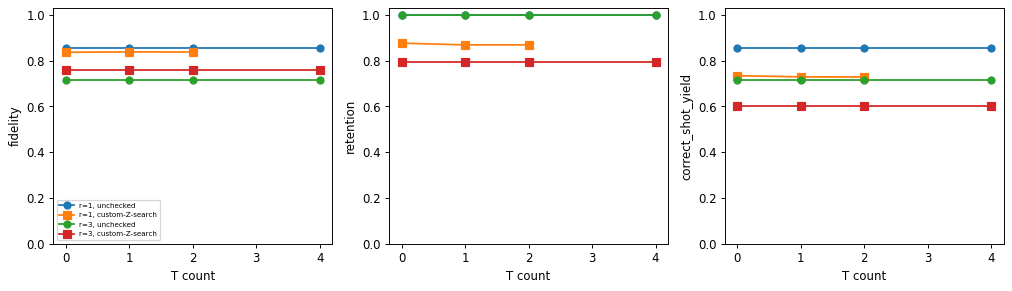

All fresh coherent and Paulice observable results match the published study.
Packages: {'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'qiskit-paulice': '0.2.1', 'numpy': '2.2.6'}
Seed: 2026 Shots per observable: 1024 Measured runtime seconds: 8.028


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12,3.5))
for repetitions in (1,3):
    for method, marker in (("unchecked", "o"),("custom-Z-search", "s")):
        selected = []
        for t in (0,1,2,4):
            group = [r for r in rows if r["repetitions"]==repetitions and r["tCount"]==t and r["method"]==method]
            selected.append(max(group, key=lambda r:r["correct_shot_yield"]) if group else None)
        for ax, metric in zip(axes, ("fidelity","retention","correct_shot_yield")):
            ax.plot([0,1,2,4], [r[metric] if r else np.nan for r in selected], marker+"-",
                    label=f"r={repetitions}, {method}")
            ax.set(xlabel="T count", ylabel=metric, ylim=(0,1.03))
axes[0].legend(fontsize=6)
fig.tight_layout()
figure(fig)
# Read published results only now, to verify an independently computed run.
published = json.loads((ROOT/"docs/TRACK_EXPERIMENTS.json").read_text(encoding="utf-8"))
assert len(rows) == len(published["rows"])
for fresh, saved in zip(rows, published["rows"]):
    for key in ("repetitions","tCount","method","addedAncillas","addedTwoQubit","addedDepth"):
        assert fresh[key] == saved[key], (key, fresh[key], saved[key])
    for key in ("fidelity","retention","correct_shot_yield","uncheckedFidelity"):
        assert abs(fresh[key]-saved[key]) < 1e-9, (key, fresh[key], saved[key])
for fresh, saved in zip(paulice_observables, published["pauliceObservableBenchmarks"]):
    for key in ("fidelity","retention","baseline","exactReference"):
        assert abs(fresh[key]-saved[key]) < 1e-9, (key, fresh[key], saved[key])
print("All fresh coherent and Paulice observable results match the published study.")
print("Packages:", {p:version(p) for p in ("qiskit","qiskit-aer","qiskit-paulice","numpy")})
print("Seed:", SEED, "Shots per observable:", SHOTS, "Measured runtime seconds:", round(time.perf_counter()-START,3))

The notebook rebuilds all results without a results-cache dependency. `scripts/run_track_experiments.py` regenerates the published comparison artifact using the same scoring functions. Main-level targets, noise and pass conditions are unchanged. Gamma/windowed is deterministic with this seed; native gamma is neither a game optimum nor a full-state fidelity.